# Chapitre 10 - Lab : les algorithmes du traitement par lots dans PostgreSQL

Les algorithmes des cours 1 à 5 ne sont pas propres aux frameworks distribués : un moteur
de base de données les emploie aussi pour ses requêtes analytiques. Ce lab les observe
dans PostgreSQL 16, à travers ses plans d'exécution (`EXPLAIN ANALYZE`) :

1. le **tri externe** : quand la mémoire de tri (`work_mem`) ne suffit plus, PostgreSQL
   trie par segments sur disque puis fusionne (cours 1) ;
2. l'**agrégation** par hachage ou par tri, et le débordement sur disque ;
3. les **algorithmes de jointure** : hachage, fusion, boucles imbriquées, et la jointure
   par hachage **partitionnée** quand la table de hachage ne tient pas en mémoire
   (cours 3) ;
4. le **chargement en masse** : insertions une à une, par lots, ou `COPY` (cours 5) ;
5. **construire puis basculer** : publier une nouvelle version d'une table d'un coup,
   sans que les lecteurs voient jamais un état intermédiaire (cours 5).

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/batch/compose.yml -p ddia_batch up -d     # démarrer
docker compose -f docker/batch/compose.yml -p ddia_batch down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **11132** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `lots`). Le parallélisme intra-requête est désactivé
(`max_parallel_workers_per_gather=0`) pour que les plans restent lisibles. Les durées
dépendent de la machine ; ce sont les ordres de grandeur et les plans qui comptent.

In [1]:
import re
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)

DSN = "host=localhost port=11132 user=ddia password=ddia dbname=lots"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    return con.execute(sql, params).fetchall()


def plan(sql):
    """Plan réel (EXPLAIN ANALYZE) sous forme de texte, sans les durées par nœud."""
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, COSTS OFF, TIMING OFF, SUMMARY OFF) " + sql))


def duree_serveur(sql, repet=3):
    """Durée médiane d'exécution côté serveur (s), lue dans EXPLAIN ANALYZE : on exclut
    ainsi le transfert des lignes vers le client, qui masquerait le coût des algorithmes."""
    ts = []
    for _ in range(repet):
        p = "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, TIMING OFF) " + sql))
        ts.append(float(re.search(r"Execution Time: ([\d.]+) ms", p).group(1)) / 1e3)
    return float(np.median(ts))


def chrono(sql, repet=3):
    """Durée médiane d'exécution vue du client (s)."""
    ts = []
    for _ in range(repet):
        t0 = time.perf_counter()
        con.execute(sql).fetchall()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (A


**Les données.** Deux tables générées côté serveur avec une graine fixe : 2 millions
d'événements (utilisateur, URL, horodatage, durée) et 200 000 utilisateurs (année de
naissance, pays), comme au cours 3.

In [2]:
q("SELECT setseed(0.42)")
con.execute("DROP TABLE IF EXISTS events, users")
con.execute("""
CREATE TABLE users AS
SELECT g AS user_id, 1940 + (random() * 70)::int AS birth,
       (ARRAY['FR','DE','US','BR','IN','JP'])[1 + (random() * 5)::int] AS country
FROM generate_series(1, 200000) g""")
con.execute("""
CREATE TABLE events AS
SELECT (1 + random() * 199999)::int AS user_id,
       '/page/' || (floor(1000 * power(random(), 3)))::int AS url,
       md5(g::text) AS session,
       timestamp '2022-11-15' + g * interval '300 ms' AS ts,
       (random() * 120)::int AS duree_s
FROM generate_series(1, 2000000) g""")
con.execute("ANALYZE users")
con.execute("ANALYZE events")
pd.DataFrame(q("""SELECT relname, n_live_tup, pg_size_pretty(pg_total_relation_size(relid))
                  FROM pg_stat_user_tables WHERE relname IN ('users', 'events') ORDER BY relname"""),
             columns=["table", "lignes", "taille"])

,table,lignes,taille
0,events,2000000,178 MB
1,users,200000,8712 kB


## 1. Le tri externe (section *Sorting versus in-memory aggregation*)

`work_mem` borne la mémoire d'**un** tri. Si les données tiennent, PostgreSQL fait un
tri rapide en mémoire (*quicksort*) ; sinon, il écrit des segments triés dans des
fichiers temporaires et les fusionne (*external merge*), exactement l'algorithme du
cours 1. Trions les 2 millions d'événements par session (une chaîne aléatoire) avec deux
réglages.

In [3]:
requete_tri = "SELECT session, user_id FROM events ORDER BY session"
for wm in ["256MB", "4MB"]:
    con.execute(f"SET work_mem = '{wm}'")
    lignes = [l for l in plan(requete_tri).splitlines() if "Sort Method" in l or "Sort Key" in l]
    print(f"work_mem = {wm} :", *lignes, sep="\n   ")

work_mem = 256MB :
     Sort Key: session
     Sort Method: quicksort  Memory: 174153kB


work_mem = 4MB :
     Sort Key: session
     Sort Method: external merge  Disk: 97928kB


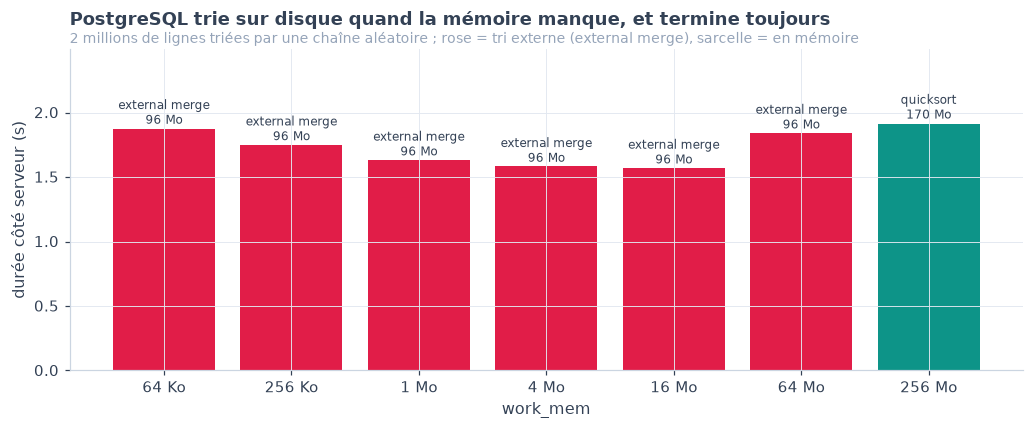

,work_mem (Ko),méthode,Ko utilisés,durée (s)
0,64,external merge,97928,1.875
1,256,external merge,97904,1.750
2,1024,external merge,97872,1.635
3,4096,external merge,97928,1.586
4,16384,external merge,97856,1.573
5,65536,external merge,97856,1.839
6,262144,quicksort,174153,1.915


In [4]:
rows = []
for wm_kb in [64, 256, 1024, 4096, 16384, 65536, 262144]:
    con.execute(f"SET work_mem = '{wm_kb}kB'")
    p = plan(requete_tri)
    m = re.search(r"Sort Method: (\w+ ?\w*)\s+(?:Memory|Disk): (\d+)kB", p)
    rows.append({"work_mem (Ko)": wm_kb, "méthode": m.group(1).strip(), "Ko utilisés": int(m.group(2)),
                 "durée (s)": duree_serveur(requete_tri, 2)})
S = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 4))
couleurs = [TEAL if "quick" in mth else ROSE for mth in S["méthode"]]
ax.bar(range(len(S)), S["durée (s)"], color=couleurs)
for i, r in S.iterrows():
    ax.text(i, r["durée (s)"] * 1.02, f"{r['méthode']}\n{r['Ko utilisés'] / 1024:.0f} Mo", ha="center", fontsize=8)
ax.set_xticks(range(len(S))); ax.set_xticklabels([f"{v // 1024} Mo" if v >= 1024 else f"{v} Ko" for v in S["work_mem (Ko)"]])
ax.set_xlabel("work_mem"); ax.set_ylabel("durée côté serveur (s)")
ax.set_ylim(0, S["durée (s)"].max() * 1.3)
ax.set_title("PostgreSQL trie sur disque quand la mémoire manque, et termine toujours")
subtitle(ax, "2 millions de lignes triées par une chaîne aléatoire ; rose = tri externe (external merge), sarcelle = en mémoire")
plt.tight_layout(); plt.show()
S

Avec 256 Mo, le tri se fait en mémoire ; en dessous, PostgreSQL passe au tri externe et
indique le volume écrit sur disque (environ 96 Mo, plus compact que les 170 Mo de
structures en mémoire). Et surprise : ici, le tri externe est **aussi rapide, voire plus
rapide**, que le tri en mémoire, même avec 64 Ko. Deux raisons. Les fichiers temporaires restent dans le
cache de pages du système : « sur disque » ne coûte presque rien. Surtout, un tri rapide
de 2 millions de lignes dispersées dans 170 Mo de mémoire multiplie les défauts de cache
du processeur, alors que le tri externe trie des segments qui tiennent dans le cache
puis les fusionne séquentiellement. Le tri externe n'est donc pas un pis-aller : c'est
un algorithme efficace, qui termine quelle que soit la mémoire, et dont le coût croît
lentement quand elle diminue (comme au cours 1).

> **À retenir.** Un moteur SQL applique le même tri externe que `sort` : segments triés
> puis fusion. `EXPLAIN ANALYZE` le révèle (*external merge*, volume disque).